## Dynamic modelling met ODE's - use case notebook
Door: Vincent de Jong, Fleur Luten
#### Inleiding dataset

In dit notebook onderzoeken we hoe verschillende wiskundige groeimodellen de groei van een tumor kunnen beschrijven. Voor deze casus gebruiken we gegevens uit een dataset met tumorvolumes van muizen genaamd "Tumor Growth Dataset", bijgedragen door Constantine Daskalakis en beschikbaar op https://www.causeweb.org/tshs/tumor-growth/.

De dataset bevat verschillende groepen muizen die gedurende een bepaalde periode zijn gevolgd voor een dierxenotransplantatie-experiment, elke met een bepaald soort behandeling voor kanker. (Controle, Drug, Radiation en Drug + Radiation)

Per muis zijn op verschillende tijdstippen metingen van het tumorvolume uitgevoerd. Omdat iedere muis een eigen groeipatroon kan hebben, richten we ons in deze notebook op één muis. Voor deze use case is door de gebruiker muis 101 gebruikt uit de controlegroep en dus geen extra variabele heeft spelen bij zijn tumor, en als tweede reden omdat de metingen het meest evenredig gespreid zijn. (Er zijn geen lange blokken van geen metingen bij het begin of einde, bijvoorbeeld)

#### Benodigde modellen

Om de groeicurve te kunnen berekenen, hebben we een differentiaalvergelijking en een solver nodig die stap voor stap de verandering in tumorvolume benadert.

Deze package bevat 6 differentiaalvergelijkingsmodellen:
________
 4.1 Lineare groei

dV/dt = c

4.2 Exponentiële groei

dV/dt = c × V

4.3 Mendelsohn groei

dV/dt = c × Vᵈ

4.4 Exponentiële afvlakking

dV/dt = c × (Vmax − V)

4.5 Logistische groei

dV/dt = c × V × (Vmax − V)

4.6 Montroll groei

dV/dt = c × V × (Vmaxᵈ − Vᵈ)

4.7 Allee effect groei

dV/dt = c × (V − Vmin) × (Vmax − V)
________
Ook bevat deze package twee ODE solvers, namelijk Euler en Heun, waarmee de verschillende groeimodellen worden doorgerekend.

Bij deze use case wil de gebruiker deze twee solvers vergelijken om te zien welke het beste de data van muis 101 kan fitten, met als verwachting dat de Heun solver een beter resultaat zal tonen dan een Euler solver, omdat uit een vergelijking in workshop 2 bleek dat Heun een kleinere fout opleverde dan Euler. Ook verliest het niet te veel nauwkeurigheid ten opzichte van een Range-Kutta solver, die lastiger te implementeren valt.

#### Data inlezen
Het Excelbestand bevat meerdere behandelgroepen. Voor deze use-case selecteren we alleen de controlegroep. De kolommen van deze groep bevatten de meetdagen en de tumorvolumes van muizen 101 tot en met 108.

De Exceldata heeft een extra kopregel, dus die wordt overgeslagen.

In [2]:
import pandas as pd

data = pd.read_excel("Data/tumorgrowth.xlsx", header=1)

# Alleen de meetdag en de muizen uit de controlegroep selecteren
control = data[["Day", 101, 102, 103, 104, 105, 106, 107, 108]].copy()

display(control)

,Day,101,102,103,104,105,106,107,108
0,0,41.8,79.4,44.8,67.7,54.7,60.0,46.8,49.4
1,1,NaN,110.3,67.5,92.4,NaN,74.2,NaN,NaN
2,2,NaN,NaN,55.8,77.7,NaN,98.9,NaN,NaN
3,3,85.0,NaN,82.8,107.4,61.1,103.3,NaN,NaN
4,4,114.0,201.3,106.8,147.1,75.3,106.4,162.6,123.2
5,5,162.3,255.3,NaN,NaN,112.5,NaN,264.5,286.5
6,6,178.3,349.1,NaN,NaN,117.8,NaN,253.1,484.9
7,7,325.0,357.5,309.5,226.1,164.9,166.3,419.3,584.5
8,8,NaN,670.0,355.9,285.3,NaN,269.2,NaN,NaN
9,9,NaN,NaN,554.8,541.5,NaN,478.4,NaN,NaN


Hierna worden alle benodigde gegevens van de gekozen muis het excel bestand gehaald. Dit zijn de gemeten tijdstippen, de gemeten tumorvolums, de begin en eindwaardes van die meetingen en de delta t.

In [19]:
import numpy as np

mouse_id = 101

mouse_data = control[["Day", mouse_id]].dropna()

t_data = mouse_data["Day"].to_numpy(dtype=float)
V_data = mouse_data[mouse_id].to_numpy(dtype=float)

V0 = V_data[0] # Begin en eindwaarden
t_start = t_data[0]
t_end = t_data[-1]

dt = np.min(np.diff(t_data)) / 10 # De kleinste afstand tussen twee meetmomenten bepaalt de delta t


Voordat we gaan beginnen, wil de onderzoeker eerst nog even kijken naar de groei van muis 101's tumor in een simpele plot.

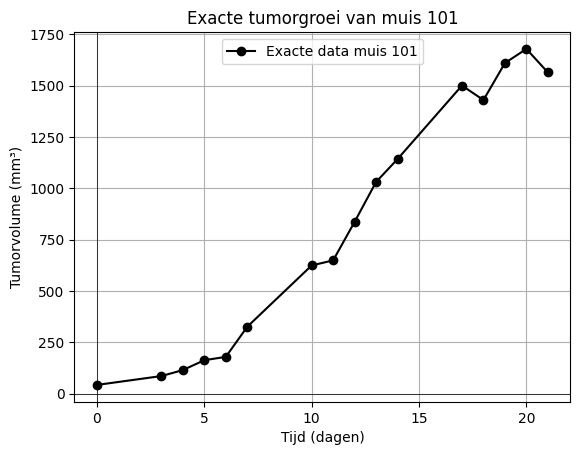

In [20]:
from matplotlib import pyplot as plt


plt.figure()
plt.grid(True)
plt.plot(t_data, V_data, "o-k", label=f"Exacte data muis {mouse_id}")
plt.axhline(0.0, lw=0.5, color='k')
plt.axvline(0.0, lw=0.5, color='k')
plt.xlabel("Tijd (dagen)")
plt.ylabel("Tumorvolume (mm³)")
plt.title(f"Exacte tumorgroei van muis {mouse_id}")
plt.legend()
plt.show()

Je ziet dat op dag 3 de groei van de tumor aan het begin best sloom verloopt, en dat pas op dag 7 er echt dikke stijging in komt. Op dag 18 krimpt de tumor voor een dag, voordat het weer groeit op dag 19 en z'n hoogst gemeten punt bereikt op dag 20. Op de laatste dag, dag 21, krimt het echter weer.

#### Optimalisatie

De groeimodellen bevatten parameters zoals c, d, Vmin en Vmax, en juiste waarden hiervoor zijn vooraf niet bekend. Hiervoor heeft de package een random search (Monte-Carlo methode) die door de gebruiker hiervoor is gekozen. Deze methode probeert zulke parameters te zoeken die de voorspelde tumorvolumes zo dicht mogelijk bij de gemeten waarden brengen.


 De fout die hiervoor wordt gebruikt is de gemiddelde kwadratische fout. (MSE) Voor ieder meetpunt wordt het verschil tussen de gemeten waarde en de modelwaarde gekwadrateerd. Daarna wordt het gemiddelde van deze kwadratische verschillen berekend. De MSE helpt de Monte-Carlo methode ook als een manier om te bepalen welk differentiaalvergelijkingsmodel het beste de data kan oplossen.

De random search verandert de parameters telkens een klein betje op een willekeurige manier. Een nieuwe set parameters wordt dan bewaard wanneer deze een lagere fout oplevert. Dit proces stopt wanneer er 1000 pogingen achter elkaar geen verbetering is gevonden.

Voor de Monte-Carlo methode geven we elk model mee die erdoor heen moet gaan. Ook geven we beginwaarden op voor de parameters. De random search gebruikt deze waarden als startpunt. Deze startparameters zijn gekozen op basis van het artikel: "Differences in predictions of ODE models of tumor growth: a cautionary example" door Hope Murphy, Hana Jaafari en Hana M Dobrovolny, en met hulp van Chatgpt.

In [21]:
from tumor_models.models import (
    mendelsohn_growth,
    exponential,
    linear,
    exponential_smooth,
    logistic,
    montroll,
    allee_effect)

from tumor_models.solver_euler import euler_solver
from tumor_models.solver_heun import heun_solver

models = {
    "Mendelsohn": mendelsohn_growth,
    "Exponential": exponential,
    "Linear": linear,
    "Exponential smooth": exponential_smooth,
    "Logistic": logistic,
    "Montroll": montroll,
    "Allee": allee_effect}

solvers = {"Euler": euler_solver, "Heun": heun_solver}

start_parameters = {
    "Mendelsohn": {"c": 0.01, "d": 1.0},
    "Exponential": {"c": 0.1},
    "Linear": {"c": 10},
    "Exponential smooth": {"c": 0.001, "Vmax": 2000},
    "Logistic": {"c": 0.00001, "Vmax": 2000},
    "Montroll": {"c": 0.000001, "d": 1.0, "Vmax": 2000},
    "Allee": {"c": 0.00001, "Vmin": 10, "Vmax": 2000}}


Hierna voeren wij de daadwerkelijke random search ook uit.

In [22]:
from random import gauss

def random_search_monte_carlo(t_data, V_data, model, solver, dt=1, **start_params):
    params = start_params.copy()
    parameters = list(params.values())

    times, predicted_volumes = solver(model, V_data[0], t_data[0], t_data[-1], dt, parameters)
    error = 0

    for i in range(len(t_data)):
        index = int(round((t_data[i] - t_data[0]) / dt))
        difference = V_data[i] - predicted_volumes[index]
        error += difference ** 2

    error = error / len(t_data)
    tries = 0

    while tries < 1000:
        tries += 1
        new_params = {
            key: val + gauss(0, 0.01)
            for key, val in params.items()}
        new_parameters = list(new_params.values())
        times, predicted_volumes = solver(model, V_data[0], t_data[0], t_data[-1], dt, new_parameters)
        new_error = 0

        for i in range(len(t_data)):
            index = int(round((t_data[i] - t_data[0]) / dt))
            difference = V_data[i] - predicted_volumes[index]
            new_error += difference ** 2

        new_error = new_error / len(t_data)

        if new_error < error:
            params = new_params
            error = new_error
            tries = 0

    return error, params

Bij deze functie worden eerst parameters van de methode gekopiëerd, om mee te geven naar de rest van de functie. Daarna wordt de fout berekend met de meegegeven solver en gekeken welke positie in de voorspelde groeicurve bij het huidige meting hoort. Het verschil tussen die twee wordt dan berekend om de MSE te krijgen. Een lagere MSE betekent dat de voorspelde groeicurve dichter bij de gemeten waarden ligt. Met gauss worden dan willekeruig heel klein veranderingen aan de huidige parameters toegevoegd. Hierdoor ontstaan nieuwe parametercombinaties waarmee dan opnieuw de groeicurve wordt berekend. De nieuwe MSE wordt dan vergeleken met de vorige MSE. Als de nieuwe fout lager is, dan zijn het betere parameters en worden de nieuwe parameters bewaard. Zo niet, dan worden de oude parameters gebruikt. Dit wordt gedaan tot 1000 pogingen achter elkaar geen verbetering in de MSE komt. Uiteindelijk geeft de functie de laagste MSE en de bijbehorende parameterwaarden terug.


#### Vergelijking

Een lagere MSE betekent niet automatisch at dit de beste verklaring voor de data is. Als je model veel parameters heeft, kan je al snel overfitting krijgen. Je hebt hiervoor drie statistische vergelijkingsmaten: BIC, AIC, en AICc. Als je een grote MSE krijgt, dan zullen deze maten ook hoger worden. Echter, deze maten zullen ook groeien bij de hoeveelheid parameters. BIC geeft strafpunten aan modellen met veel parameters en hoge metingen, AIC geeft strafpunten aan parameters maar de grote maakt hem niet zo veel uit en AICc geeft een correctie aan met datasets met een relatief kleine hoeveelheid meetgegevens.

De onderzoeker gaat de modellen na monte carlo door 3 comparison functies heen halen, om te zien of de gemiddelde kwadraatische fout niet door overfitting komt.

In [24]:
from math import log

def calculate_aic(error, n, k):
    return n * log(error) + 2 * k


def calculate_aicc(error, n, k):
    return n * log(error) + (2 * k * n) / (n - k - 1)


def calculate_bic(error, n, k):
    return n * log(error) + k * log(n)

Deze drie functies gebruiken van alle modellen: de MSE, het aantal meetpunten en het aantal parameters om de BIC, AIC en AICc waardes te vinden.



In [25]:
def compare_models(t_data, V_data, models, solvers, start_parameters, dt=1):
    results = []
    n = len(t_data)

    for model_name, model in models.items():
        for solver_name, solver in solvers.items():
            error, params = random_search_monte_carlo(t_data, V_data, model, solver, dt,**start_parameters[model_name])
            k = len(params)

            if error > 0:
                aic = calculate_aic(error, n, k)
                aicc = calculate_aicc(error, n, k)
                bic = calculate_bic(error, n, k)
            else:
                aic = None
                aicc = None
                bic = None

            results.append({"model": model_name, "solver": solver_name, "error": error, "parameters": params,
            "AIC": aic, "AICc": aicc, "BIC": bic})

    return results

De resultaten bevatten per combinatie het groeimodel, de solver, de gevonden parameters, de gemiddelde kwadratische fout en de drie vergelijkingsmaten. We zetten de resultaten in een tabel en sorteren ze op BIC, zodat de laagste BIC-score bovenaan staat. We krijgen hier een paar overflow errors, sommige random search berekeningen gingen buiten de scope van python om. Omdat deze daardoor waarschijnlijk een te hoge MSE bevatten, worden deze overgeslagen, en gaat de random search doormet nieuw parameters tot er na 1000 poging geen verbetering in de MSE te vinden is.

In [41]:
results = compare_models(t_data, V_data, models, solvers, start_parameters, dt=dt)

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="BIC")

display(results_df)

C:\Users\vdejo\PycharmProjects\Kankermodell\ModellerenVanKankerCasusA\tumor_models\models.py:53: RuntimeWarning: overflow encountered in scalar multiply
  return c * V * (Vmax - V)
C:\Users\vdejo\AppData\Local\Temp\ipykernel_23172\1767968125.py:30: RuntimeWarning: overflow encountered in scalar power
  new_error += difference ** 2
C:\Users\vdejo\PycharmProjects\Kankermodell\ModellerenVanKankerCasusA\tumor_models\models.py:65: RuntimeWarning: invalid value encountered in scalar power
  return c * V * (Vmax**d - V**d)
C:\Users\vdejo\PycharmProjects\Kankermodell\ModellerenVanKankerCasusA\tumor_models\models.py:78: RuntimeWarning: overflow encountered in scalar multiply
  return c * (V - Vmin) * (Vmax - V)


,model,solver,error,parameters,AIC,AICc,BIC
10,Montroll,Euler,7207.794380,"{'c': 0.0001859113576930865, 'd': 0.9644233505...",148.126692,150.126692,150.444459
9,Logistic,Heun,9344.476528,"{'c': 0.0001360374630339188, 'Vmax': 1999.9959...",150.280651,151.203728,151.825829
11,Montroll,Heun,8394.762202,"{'c': 9.391648831813364e-05, 'd': 1.0556454339...",150.565812,152.565812,152.883578
0,Mendelsohn,Euler,11730.038442,"{'c': 7.00119561544788, 'd': 0.38547984286544557}",153.918532,154.841608,155.463709
1,Mendelsohn,Heun,11750.292090,"{'c': 6.867130201735692, 'd': 0.3880361486304524}",153.946134,154.869211,155.491311
13,Allee,Heun,18913.590539,"{'c': 0.0001401639402999169, 'Vmin': 9.9751280...",163.562176,165.562176,165.879942
5,Linear,Heun,29395.653804,{'c': 74.00608044000558},166.617634,166.903348,167.390223
4,Linear,Euler,29395.653804,{'c': 74.00607364333197},166.617634,166.903348,167.390223
12,Allee,Euler,37318.942479,"{'c': 0.00013406789844053023, 'Vmin': 10.03351...",174.436101,176.436101,176.753867
8,Logistic,Euler,56697.209497,"{'c': 0.00017356946724703982, 'Vmax': 2000.001...",179.127684,180.050761,180.672862


We zien dat in het algemeen na verschillende tests, dat de logistische modellen via beide solvers de beste resultaten hadden. Ook de montroll modellen scoren aardig hoog. De exponentiële modellen scoren allebei vrij laag. Wat erg opvalt is dat bij een van de runs, het Allee model via de Euler solver ook goed scoort, maar dat het resultaat van de Heun solver juist een stuk lager is. De onderzoeker vermoed omdat de groeisnelheid heel erg afhangt is van de zowel de vmin als vmax. Kleine verschillen in de parameters die door Random Search gevonden worden kunnen misschien dan een groter effect hebben op de MSE dan bij andere modellen.

Om de verschillen nog even wat te verduidelijken, maken we een plot van de voorspelde groei van elk model.

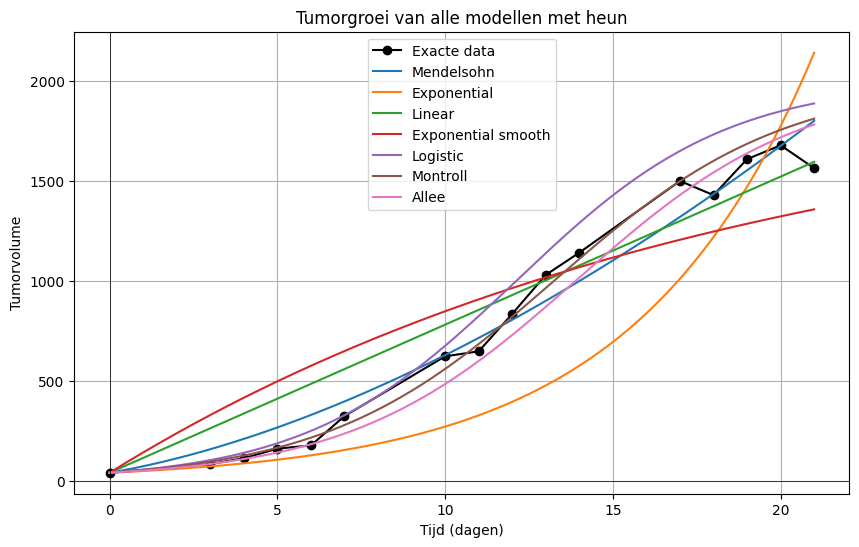

In [39]:
plt.figure(figsize=(10, 6))

plt.plot(t_data, V_data, 'o-k', label='Exacte data')

for result in results:
    if result["solver"] == "Heun":
        model_name = result["model"]
        model = models[model_name]
        parameters = list(result["parameters"].values())

        ts_numer, Vs_numer = heun_solver(model, V_data[0], t_data[0], t_data[-1], dt, parameters)
        plt.plot(ts_numer, Vs_numer, label=model_name)

plt.axhline(0.0, lw=0.5, color='k')
plt.axvline(0.0, lw=0.5, color='k')

plt.grid(True)
plt.legend()
plt.xlabel('Tijd (dagen)')
plt.ylabel('Tumorvolume')
plt.title('Tumorgroei van alle modellen met heun')
plt.show()

#### Beste model

Omdat het logistiche model en de montroll als beste uit de vergelijking kwamen, worden deze geisoleerd tot hun eigen vergelijkingen met de exacte data.

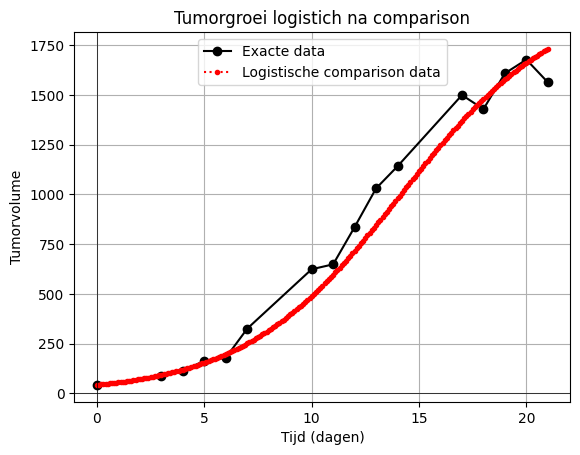

In [42]:
c = 0.0001360374630339188
Vmax = 1999.9959342341958

ts_numer, Vs_numer = heun_solver(
    logistic, V_data[0], t_data[0], t_data[-1], dt, [c, Vmax])

plt.plot(t_data, V_data, 'o-k', label='Exacte data')
plt.plot(ts_numer, Vs_numer, '.:r', label='Logistische comparison data')

plt.axhline(0.0, lw=0.5, color='k')
plt.axvline(0.0, lw=0.5, color='k')

plt.grid(True)
plt.legend()
plt.xlabel('Tijd (dagen)')
plt.ylabel('Tumorvolume')
plt.title('Tumorgroei logistich na comparison')
plt.show()

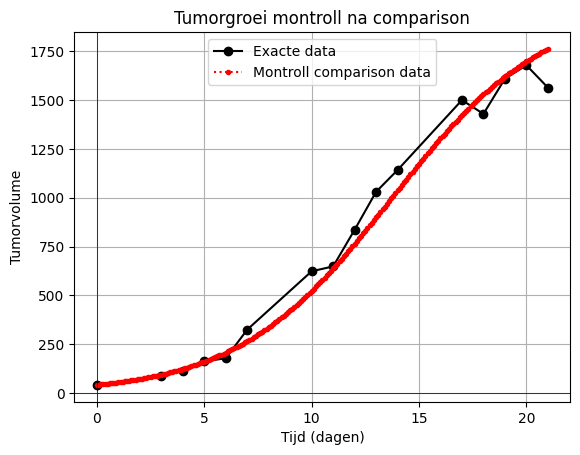

In [49]:
c = 0.0001859113576930865
d = 0.9644233505910363
Vmax = 2000.035617765038

ts_numer, Vs_numer = heun_solver(
    montroll, V_data[0], t_data[0], t_data[-1], dt, [c, d, Vmax])

plt.plot(t_data, V_data, 'o-k', label='Exacte data')
plt.plot(ts_numer, Vs_numer, '.:r', label='Montroll comparison data')

plt.axhline(0.0, lw=0.5, color='k')
plt.axvline(0.0, lw=0.5, color='k')

plt.grid(True)
plt.legend()
plt.xlabel('Tijd (dagen)')
plt.ylabel('Tumorvolume')
plt.title('Tumorgroei montroll na comparison')
plt.show()

Dat een logistische model goed uit de vergelijking komt, is waarschijnlijk omdat in het begin de tumor relatief langzaam groeit. Daarna neemt de groeisnelheid toe. Wanneer het tumorvolume dichter bij de Vmax komt, neemt de groeisnelheid weer af. Ook heeft het logistische model maar twee parameters en krijgt het dus geen extra straf voor overfitten door te complexe parameters.

Het montroll model komt ook erg overeen met de data van muis 101. Vmax geeft, net zoals bij het logistische model, een afname aan de groei als de volume daar in de buurt komt, De d bepaalt hierbij hoe het verschil tussen Vmax en de Vd beïnvloed wordt door de verhouding tussen het huidige volume en de Vmax.

Op basis van de resultaten lijkt het montroll model in combinatie met de Heun-solver het beste te passen bij de gebruikte data van muis 101. Deze combinatie heeft vaak laagste scores voor alle vergelijkingsmaten (MSE, AIC, AICc en BIC). Ook heeft het montroll model drie parameters, hierdoor wordt het montroll model dus meer bestraft voor complexiteit, en toch heeft het vaak een BIC, AIC en AICc resultaat vergelijkbaar of zelfs beter dan het logistiche model, die een voorsprongetje heeft met maar twee parameters. Voor deze dataset van muis 101 zal het volgens de onderzoeker echter niet al te veel uitmaken, aangezien het verschil tussen de waardes montroll en logistic niet al te significant zijn.

#### Bronnen en referenties

Gebruikte dataset: Constantine Daskalakis, “Tumor Growth Dataset”, TSHS Resources Portal (2016). https://www.causeweb.org/tshs/tumor-growth/.
___
Murphy H, Jaafari H, Dobrovolny HM. Differences in predictions of ODE models of tumor growth: a cautionary example. BMC Cancer. 2016 Feb 26;16:163. doi: 10.1186/s12885-016-2164-x. PMID: 26921070; PMCID: PMC4768423. https://pmc.ncbi.nlm.nih.gov/articles/PMC4768423/
___
D.R.M. Langers, “Casus Dynamic Modelling (ODEs)” Brightspace, 2025. https://brightspace.hanze.nl/d2l/le/lessons/71129/topics/1040474
___
The SciPy community, Resampling and Monte Carlo methods tutorials, 2008. https://docs.scipy.org/doc/scipy/tutorial/stats/resampling.html
___
